# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset

**Sections**
1. Setup and data loading
2. Exploratory Data Analysis
3. Preprocessing
4. Train/Test split
5. SVM model, tuning, cross validation
6. Prediction function
7. Advanced analysis
   - 7.1 Confusion matrix, ROC curve, Precision-Recall curve
   - 7.2 Model comparison (SVM, Naive Bayes, Logistic Regression, Random Forest)
   - 7.3 Top spam and ham words
   - 7.4 Error analysis
   - 7.5 Class imbalance check
8. Summary

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn

In [2]:
import os, re, string, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Folder to save plots (used in the README)
os.makedirs("images", exist_ok=True)

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be

## 1. Load dataset
Put `SMS.csv` (the Kaggle `spam.csv`, renamed) in the same folder as this notebook.
On Google Colab, if the file is not found, an upload box will appear.

In [3]:
if not os.path.exists("SMS.csv"):
    from google.colab import files
    uploaded = files.upload()

df = pd.read_csv("SMS.csv", encoding="latin-1")
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

In [4]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['label'].value_counts())

(5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## 2. Exploratory Data Analysis

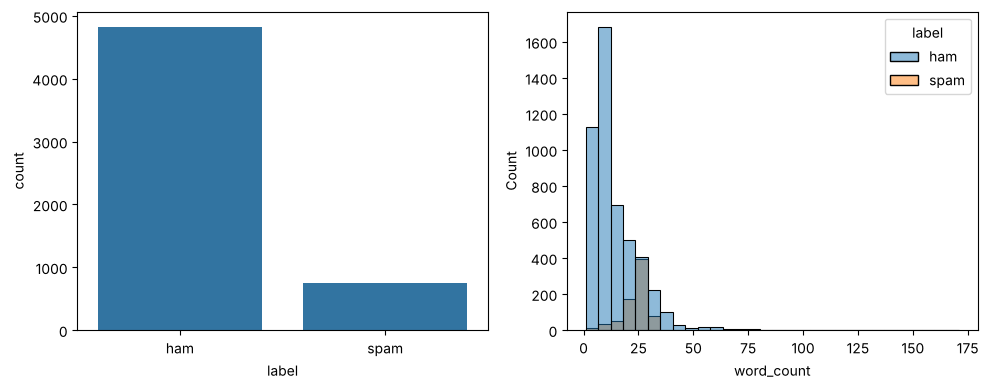

       char_count  word_count
label                        
ham          71.0        14.2
spam        138.9        23.9


In [5]:
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x='label', ax=ax[0])
sns.histplot(data=df, x='word_count', hue='label', bins=30, ax=ax[1])
plt.tight_layout()
plt.savefig("images/eda_counts.png")
plt.show()

# Average length of spam vs ham
print(df.groupby('label')[['char_count', 'word_count']].mean().round(1))

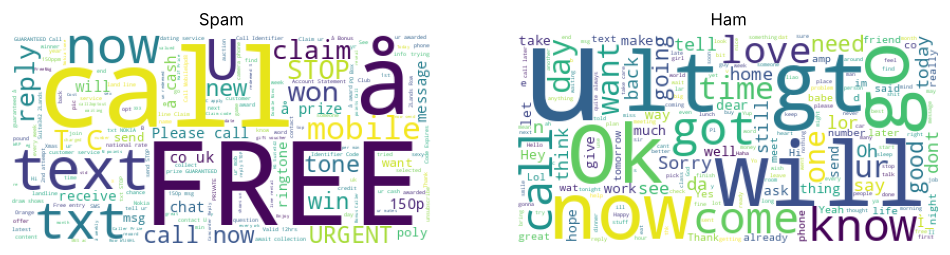

In [6]:
spam = ' '.join(df[df.label == 'spam'].message)
ham = ' '.join(df[df.label == 'ham'].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.savefig("images/wordclouds.png")
plt.show()

## 3. Preprocessing

In [7]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split into words, remove stopwords, convert each word to its base form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Clean every message
df['clean_message'] = df['message'].apply(clean_text)

# ham -> 0, spam -> 1
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## 4. Train/Test Split

In [8]:
X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(4135,)
(1034,)


## 5. SVM Model

In [9]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC())
])

pipeline.fit(X_train, y_train)
pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.9835589941972921
Precision: 0.9830508474576272
Recall: 0.8854961832061069
F1: 0.9317269076305221
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



### Hyperparameter Tuning

In [10]:
param_grid = {
    'svm__C': [0.1, 1, 10]
}
grid = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


### Cross Validation

In [11]:
scores = cross_val_score(grid.best_estimator_, df['clean_message'], df['label'], cv=5)
print(scores)
print("Mean Accuracy:", scores.mean())

[0.97969052 0.9787234  0.97969052 0.9787234  0.97483059]
Mean Accuracy: 0.9783316887022269


## 6. Prediction Function

In [12]:
model = grid.best_estimator_

def predict_sms(text):
    pred = model.predict([clean_text(text)])[0]
    return "Spam" if pred == 1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))

Spam
Ham


# 7. Advanced Analysis
Everything below uses the tuned SVM (`model`) and the same train/test split.

## 7.1 Confusion Matrix, ROC Curve and Precision-Recall Curve
Accuracy alone hides how many spam messages slip through. The confusion matrix shows the exact counts.
`LinearSVC` does not give probabilities, so we use `decision_function()` (a score, higher means more spam-like) for the curves.

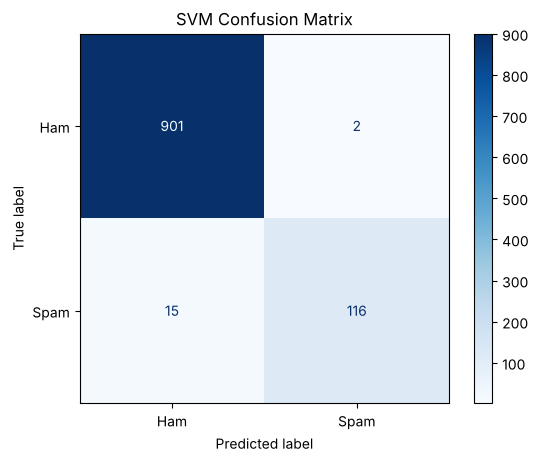

True Ham  (correct): 901
False Spam (ham marked as spam): 2
Missed Spam (spam marked as ham): 15
True Spam (correct): 116


In [13]:
y_pred = model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(cmap='Blues')
plt.title("SVM Confusion Matrix")
plt.savefig("images/confusion_matrix.png")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True Ham  (correct):", tn)
print("False Spam (ham marked as spam):", fp)
print("Missed Spam (spam marked as ham):", fn)
print("True Spam (correct):", tp)

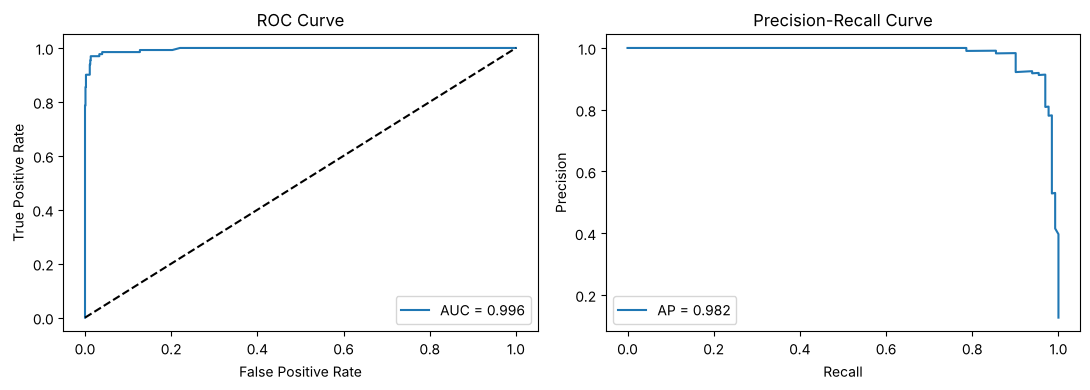

ROC AUC: 0.9959
Average Precision: 0.9818


In [14]:
# Scores from the SVM (distance from the decision boundary)
y_score = model.decision_function(X_test)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

# Precision-Recall curve (better for imbalanced data)
prec, rec, _ = precision_recall_curve(y_test, y_score)
ap = average_precision_score(y_test, y_score)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(fpr, tpr, label="AUC = " + str(round(roc_auc, 3)))
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC Curve")
ax[0].legend()

ax[1].plot(rec, prec, label="AP = " + str(round(ap, 3)))
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall Curve")
ax[1].legend()

plt.tight_layout()
plt.savefig("images/roc_pr_curves.png")
plt.show()

print("ROC AUC:", round(roc_auc, 4))
print("Average Precision:", round(ap, 4))

## 7.2 Model Comparison
Is SVM actually the best choice? Here four common text classifiers are trained on the exact same TF-IDF features and split.

In [15]:
models = {
    "Linear SVM": LinearSVC(C=grid.best_params_['svm__C']),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)
}

results = []

for name, clf in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('clf', clf)
    ])

    start = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start

    p = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
        "Train time (s)": train_time
    })

results_df = pd.DataFrame(results).round(4)
results_df = results_df.sort_values("F1", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1,Train time (s)
0,Linear SVM,0.9836,0.9831,0.8855,0.9317,0.0877
3,Random Forest,0.9729,0.9813,0.8015,0.8824,2.0239
1,Naive Bayes,0.9662,0.9898,0.7405,0.8472,0.0750
2,Logistic Regression,0.9574,1.0000,0.6641,0.7982,0.0890


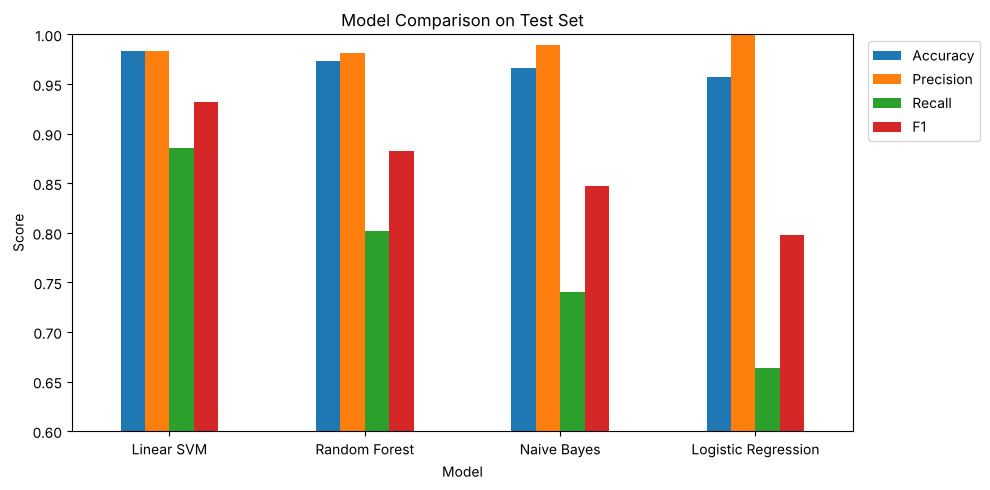

In [16]:
# Bar chart of the four metrics for each model
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]
plot_df.plot(kind='bar', figsize=(10, 5))
plt.ylim(0.6, 1.0)
plt.title("Model Comparison on Test Set")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig("images/model_comparison.png")
plt.show()

In [17]:
# 5-fold cross validation F1 for each model (more reliable than one split)
cv_results = []

for name, clf in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('clf', clf)
    ])
    f1_scores = cross_val_score(pipe, X, y, cv=5, scoring='f1')
    cv_results.append({
        "Model": name,
        "Mean CV F1": round(f1_scores.mean(), 4),
        "Std": round(f1_scores.std(), 4)
    })

pd.DataFrame(cv_results).sort_values("Mean CV F1", ascending=False)

,Model,Mean CV F1,Std
0,Linear SVM,0.9088,0.0070
3,Random Forest,0.8733,0.0280
1,Naive Bayes,0.8482,0.0222
2,Logistic Regression,0.8091,0.0224


## 7.3 Top Spam and Ham Words
Two views:
1. **Frequency:** which words appear most in each class.
2. **SVM weights:** which words the model itself relies on. A large positive weight pushes a message toward spam, a large negative weight pushes it toward ham.

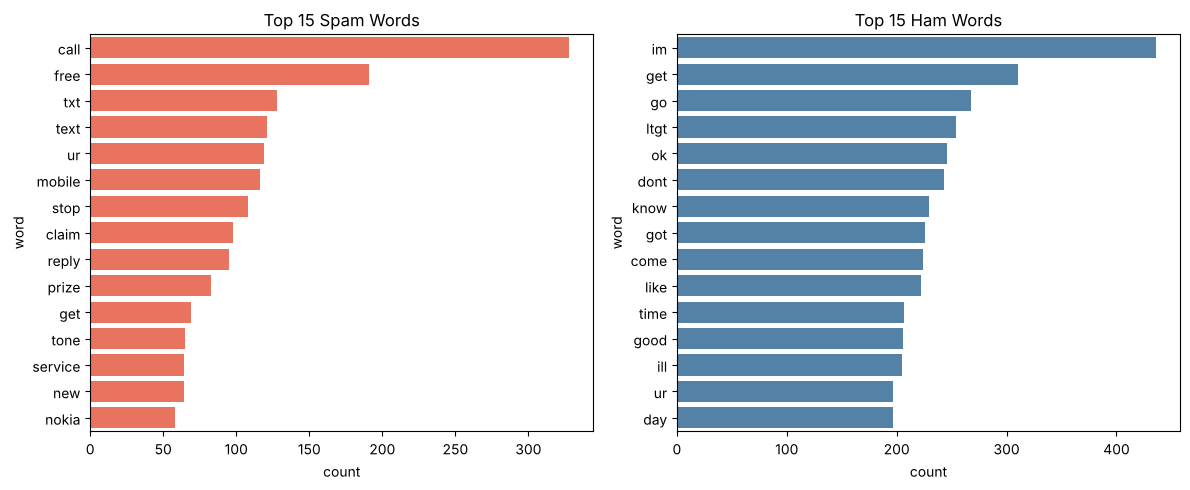

In [18]:
# Most frequent single words in spam and ham
def top_words(texts, n=15, ngram=(1, 1)):
    cv = CountVectorizer(ngram_range=ngram)
    counts = cv.fit_transform(texts)
    total = counts.sum(axis=0).A1          # total count of each word
    words = cv.get_feature_names_out()
    word_df = pd.DataFrame({"word": words, "count": total})
    return word_df.sort_values("count", ascending=False).head(n)

spam_words = top_words(df[df.label == 1]['clean_message'])
ham_words = top_words(df[df.label == 0]['clean_message'])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=spam_words, x='count', y='word', ax=ax[0], color='tomato')
ax[0].set_title("Top 15 Spam Words")
sns.barplot(data=ham_words, x='count', y='word', ax=ax[1], color='steelblue')
ax[1].set_title("Top 15 Ham Words")
plt.tight_layout()
plt.savefig("images/top_words.png")
plt.show()

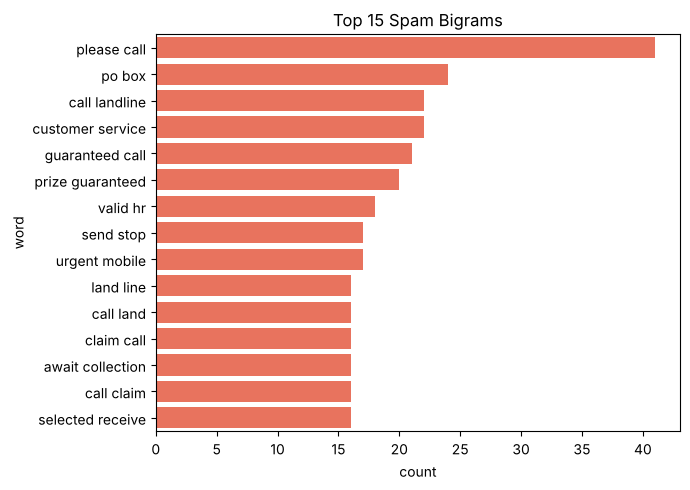

In [19]:
# Most frequent two-word phrases (bigrams) in spam
spam_bigrams = top_words(df[df.label == 1]['clean_message'], n=15, ngram=(2, 2))

plt.figure(figsize=(7, 5))
sns.barplot(data=spam_bigrams, x='count', y='word', color='tomato')
plt.title("Top 15 Spam Bigrams")
plt.tight_layout()
plt.savefig("images/spam_bigrams.png")
plt.show()

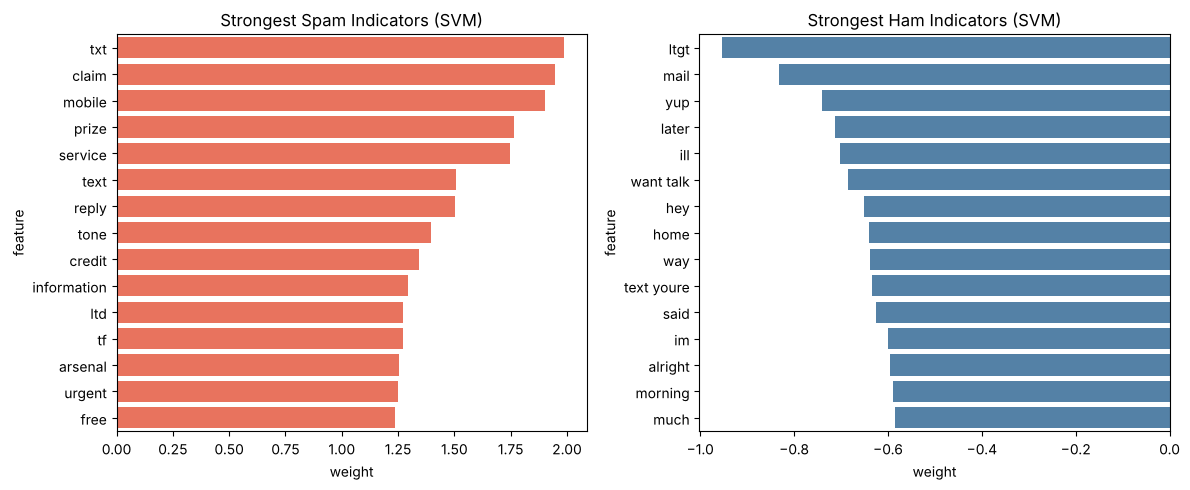

In [20]:
# Words the SVM weights the most
tfidf = model.named_steps['tfidf']
svm = model.named_steps['svm']

feature_names = tfidf.get_feature_names_out()
weights = svm.coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "weight": weights})
top_spam = coef_df.sort_values("weight", ascending=False).head(15)
top_ham = coef_df.sort_values("weight").head(15)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=top_spam, x='weight', y='feature', ax=ax[0], color='tomato')
ax[0].set_title("Strongest Spam Indicators (SVM)")
sns.barplot(data=top_ham, x='weight', y='feature', ax=ax[1], color='steelblue')
ax[1].set_title("Strongest Ham Indicators (SVM)")
plt.tight_layout()
plt.savefig("images/svm_weights.png")
plt.show()

## 7.4 Error Analysis
Looking at the actual messages the model got wrong usually tells you more than another metric.

In [21]:
# Put test results in one table, with the original (uncleaned) message
errors = pd.DataFrame({
    "message": df.loc[X_test.index, 'message'],
    "clean_message": X_test,
    "actual": y_test,
    "predicted": y_pred,
    "score": y_score
})

errors = errors[errors.actual != errors.predicted]

missed_spam = errors[errors.actual == 1]   # spam predicted as ham
false_spam = errors[errors.actual == 0]    # ham predicted as spam

print("Total errors:", len(errors), "out of", len(y_test))
print("Missed spam (false negatives):", len(missed_spam))
print("Ham flagged as spam (false positives):", len(false_spam))

Total errors: 17 out of 1034
Missed spam (false negatives): 15
Ham flagged as spam (false positives): 2


In [22]:
# Show missed spam messages (full text)
pd.set_option('display.max_colwidth', None)
missed_spam[['message', 'score']].head(10)

,message,score
5540,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O å£250 3 WANT å£800,-0.303073
1468,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Callså£1/minMobsmoreLKPOBOX177HP51FL,-0.166097
4211,Missed call alert. These numbers called but left no message. 07008009200,-0.559271
671,SMS. ac sun0819 posts HELLO:\You seem cool,-0.253387
2401,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),-0.200283
4819,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,-0.000580
2268,88066 FROM 88066 LOST 3POUND HELP,-0.016523
4142,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",-0.810476
3528,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",-0.300799
4147,Please call Amanda with regard to renewing or upgrading your current T-Mobile handset free of charge. Offer ends today. Tel 0845 021 3680 subject to T's and C's,-0.317120


In [23]:
false_spam[['message', 'score']]

,message,score
1855,K.:)you are the only girl waiting in reception ah?,0.140414
5157,K k:) sms chat with me.,0.387476


In [24]:
# Compare message length (in words) of wrong vs correct predictions
test_df = pd.DataFrame({
    "words": df.loc[X_test.index, 'word_count'],
    "correct": (y_test == y_pred)
})
print(test_df.groupby('correct')['words'].mean().round(1))

# Compare length of missed spam vs all spam in test set
print("Avg words, missed spam:", round(df.loc[missed_spam.index, 'word_count'].mean(), 1))
print("Avg words, all test spam:", round(df.loc[y_test[y_test == 1].index, 'word_count'].mean(), 1))

correct
False    18.0
True     15.7
Name: words, dtype: float64
Avg words, missed spam: 19.4
Avg words, all test spam: 23.9


## 7.5 Class Imbalance Check
Only about 13% of messages are spam. The SVM can get high accuracy by leaning toward "ham", which is why spam recall is lower than precision.
`class_weight='balanced'` tells the SVM to treat a mistake on the smaller class (spam) as more costly.

In [25]:
# Class ratio
print(df['label'].value_counts(normalize=True).round(3))

# Default SVM vs balanced SVM
svm_default = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC(C=grid.best_params_['svm__C']))
])

svm_balanced = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC(C=grid.best_params_['svm__C'], class_weight='balanced'))
])

svm_default.fit(X_train, y_train)
svm_balanced.fit(X_train, y_train)

p_default = svm_default.predict(X_test)
p_balanced = svm_balanced.predict(X_test)

compare = pd.DataFrame({
    "Default": [accuracy_score(y_test, p_default), precision_score(y_test, p_default),
                recall_score(y_test, p_default), f1_score(y_test, p_default)],
    "Balanced": [accuracy_score(y_test, p_balanced), precision_score(y_test, p_balanced),
                 recall_score(y_test, p_balanced), f1_score(y_test, p_balanced)]
}, index=["Accuracy", "Precision", "Recall", "F1"]).round(4)

compare

label
0    0.874
1    0.126
Name: proportion, dtype: float64


,Default,Balanced
Accuracy,0.9836,0.9778
Precision,0.9831,0.9219
Recall,0.8855,0.9008
F1,0.9317,0.9112


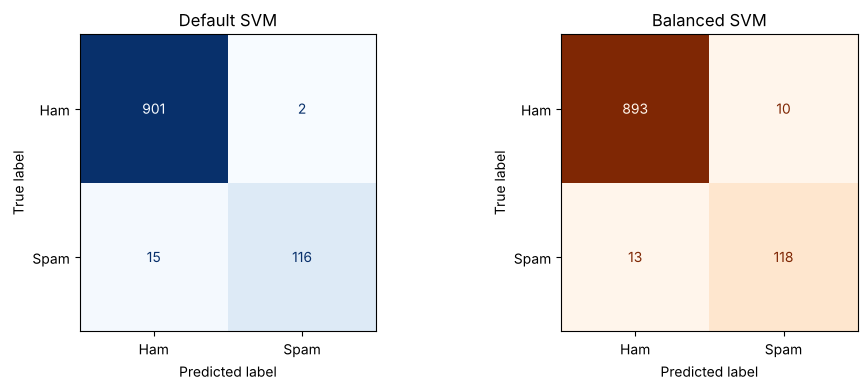

In [26]:
# Side by side confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_default),
                       display_labels=['Ham', 'Spam']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Default SVM")
ConfusionMatrixDisplay(confusion_matrix(y_test, p_balanced),
                       display_labels=['Ham', 'Spam']).plot(ax=ax[1], cmap='Oranges', colorbar=False)
ax[1].set_title("Balanced SVM")
plt.tight_layout()
plt.savefig("images/imbalance_confusion.png")
plt.show()

In [27]:
# Simple threshold test: instead of cutting at score 0,
# try a few lower cut-offs to catch more spam
thresholds = [0.0, -0.1, -0.2, -0.3, -0.4, -0.5]
rows = []

for t in thresholds:
    p = (y_score > t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": round(precision_score(y_test, p), 4),
        "Recall": round(recall_score(y_test, p), 4),
        "F1": round(f1_score(y_test, p), 4)
    })

pd.DataFrame(rows)

,Threshold,Precision,Recall,F1
0,0.0,0.9831,0.8855,0.9317
1,-0.1,0.9516,0.9008,0.9255
2,-0.2,0.9225,0.9084,0.9154
3,-0.3,0.9179,0.9389,0.9283
4,-0.4,0.8819,0.9695,0.9236
5,-0.5,0.8301,0.9695,0.8944


## 8. Summary

| Analysis | What it showed |
|---|---|
| Confusion matrix | 17 errors out of 1034 test messages. 15 are missed spam, only 2 are ham flagged as spam. |
| ROC / PR curves | ROC AUC 0.996, Average Precision 0.982. The SVM ranks spam very well; the default cut-off is just a bit strict. |
| Model comparison | Linear SVM has the best F1 on the test set (0.932) and in 5-fold CV (0.909). Logistic Regression and Naive Bayes reach very high precision but miss far more spam. Random Forest is second but about 20x slower to train. |
| Top words | Spam leans on "txt", "claim", "mobile", "prize", "free", "urgent". Ham is casual chat: "later", "home", "hey", "yup". |
| Error analysis | Missed spam is usually short or looks like normal chat (adult chat lines, quiz texts, "missed call alert"). At least one "spam" label looks like a real customer complaint, so a few errors are label noise. |
| Class imbalance | Only 12.6% of messages are spam. `class_weight='balanced'` raises recall (0.886 to 0.901) but drops precision more, so F1 falls. Lowering the decision threshold to -0.3 gives recall 0.939 with F1 0.928, close to the default. |

**Takeaways**
- Linear SVM with TF-IDF is the right pick for this dataset.
- The main weakness is recall on spam, not accuracy. If missing spam is worse than a false alarm, use a threshold around -0.3.
- Preprocessing removes all digits, but spam often contains phone numbers and short codes (e.g. 87121). Keeping a "has number" feature is a likely next improvement.